# Test adaptive bottleneck
The purpose of this notebook is to test the adaptive bottleneck on the block comparison task, a task that we know the self attention mechanism can't solve.

## Imports

In [1]:
import jax
import jax.numpy as jnp
from jax import random
import optax
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

from adaptive_bottleneck.models import init_gamma_value_attn_params, gamma_value_attention_forward
from adaptive_bottleneck.tasks import BlockComparisonDatasetTF

## Workbench

In [2]:
def init_classifier_params(key, head_dim, seq_len):
    k1, k2 = random.split(key)
    W_out = 0.02 * random.normal(k1, (seq_len * head_dim, 1))
    b_out = jnp.zeros((1,))
    return {"W_out": W_out, "b_out": b_out}


def forward_logits(params_attn, params_clf, X, gamma,):
    """
    X: (B, L, D_in)
    returns logits: (B,)
    """
    out, attn_w = gamma_value_attention_forward(
        params_attn, X, gamma=gamma, use_pos_proj=True
    )  # out: (B, L, D_h)

    flat = out.reshape(out.shape[0], -1)  # (B, L * D_h)
    logits = (flat @ params_clf["W_out"]).squeeze(-1) + params_clf["b_out"][0]
    return logits, attn_w

In [3]:
def bce_with_logits(logits, y):
    """
    y: (B,) in {0,1}
    """
    # optax.sigmoid_binary_cross_entropy expects labels in [0,1]
    return optax.sigmoid_binary_cross_entropy(logits, y).mean()


def accuracy_from_logits(logits, y):
    preds = (jax.nn.sigmoid(logits) >= 0.5).astype(jnp.float32)
    return (preds == y).mean()

In [4]:
def make_train_step(optimizer, gamma,):
    @jax.jit
    def train_step(params, opt_state, X, y):
        params_attn, params_clf = params["attn"], params["clf"]

        def loss_fn(p_attn, p_clf):
            logits, _ = forward_logits(p_attn, p_clf, X, gamma=gamma,)
            return bce_with_logits(logits, y)

        grads_attn, grads_clf = jax.grad(loss_fn, argnums=(0, 1))(params_attn, params_clf)
        grads = {"attn": grads_attn, "clf": grads_clf}

        updates, opt_state = optimizer.update(grads, opt_state, params)
        params = optax.apply_updates(params, updates)

        # metrics
        logits, _ = forward_logits(params["attn"], params["clf"], X, gamma=gamma,)
        loss = bce_with_logits(logits, y)
        acc = accuracy_from_logits(logits, y)
        return params, opt_state, loss, acc

    return train_step


@jax.jit
def eval_step(params, X, y, gamma,):
    logits, _ = forward_logits(params["attn"], params["clf"], X, gamma=gamma,)
    return bce_with_logits(logits, y), accuracy_from_logits(logits, y)

In [5]:
def tfds_to_numpy_iter(tf_dataset):
    # yields (X_np, y_np) where each is a numpy array
    return tf_dataset.as_numpy_iterator()

In [6]:
def run_gamma_sweep(
    seed=0,
    gammas=(0.0, 0.25, 0.5, 0.75, 1.0),
    num_samples=2000,
    num_vectors=2,
    vector_len=2,      # IMPORTANT: ensures D_in == L == 2 here
    batch_size=64,
    epochs=50,
    lr=1e-3,
    weight_decay=1e-4,
):
    # Create task (train/test separate keys for clean eval)
    key = random.PRNGKey(seed)
    key_train, key_test, key_init = random.split(key, 3)

    task_train = BlockComparisonDatasetTF(
        key_train,
        num_samples=num_samples,
        num_vectors=num_vectors,
        vector_len=vector_len,
    )
    ds_train = task_train.generate_tf_dataset(batch_size=batch_size, shuffle=True)

    task_test = BlockComparisonDatasetTF(
        key_test,
        num_samples=num_samples,
        num_vectors=num_vectors,
        vector_len=vector_len,
    )
    ds_test = task_test.generate_tf_dataset(batch_size=batch_size, shuffle=False)

    # Model dims
    embed_dim = vector_len   # D_in
    head_dim = vector_len    # you can set this bigger if you want
    max_seq_len = num_vectors  # L

    results = {}

    for gamma in gammas:
        # init params
        k_attn, k_clf = random.split(key_init)
        params_attn = init_gamma_value_attn_params(
            k_attn,
            embed_dim=embed_dim,
            head_dim=head_dim,
            max_seq_len=max_seq_len,
            use_pos_proj=True,   # harmless even if D_in==L
            scale=0.02,
        )
        
        params_clf = init_classifier_params(k_clf, head_dim=head_dim, seq_len=num_vectors)
        params = {"attn": params_attn, "clf": params_clf}

        # optimizer
        optimizer = optax.adamw(learning_rate=lr, weight_decay=weight_decay)
        opt_state = optimizer.init(params)

        train_step = make_train_step(optimizer, gamma=jnp.array(gamma, dtype=jnp.float32),)

        history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

        for epoch in range(epochs):
            # ---- Train epoch ----
            train_losses = []
            train_accs = []
            for X_np, y_np in tfds_to_numpy_iter(ds_train):
                X = jnp.asarray(X_np, dtype=jnp.float32)
                y = jnp.asarray(y_np, dtype=jnp.float32).reshape(-1)  # (B,)
                params, opt_state, loss, acc = train_step(params, opt_state, X, y)
                train_losses.append(loss)
                train_accs.append(acc)

            # ---- Eval epoch ----
            test_losses = []
            test_accs = []
            for X_np, y_np in tfds_to_numpy_iter(ds_test):
                X = jnp.asarray(X_np, dtype=jnp.float32)
                y = jnp.asarray(y_np, dtype=jnp.float32).reshape(-1)
                loss, acc = eval_step(params, X, y, gamma=jnp.array(gamma, dtype=jnp.float32),)
                test_losses.append(loss)
                test_accs.append(acc)

            # aggregate
            tr_loss = float(jnp.mean(jnp.stack(train_losses)))
            tr_acc  = float(jnp.mean(jnp.stack(train_accs)))
            te_loss = float(jnp.mean(jnp.stack(test_losses)))
            te_acc  = float(jnp.mean(jnp.stack(test_accs)))

            history["train_loss"].append(tr_loss)
            history["train_acc"].append(tr_acc)
            history["test_loss"].append(te_loss)
            history["test_acc"].append(te_acc)

            if (epoch % max(1, epochs // 10) == 0) or (epoch == epochs - 1):
                print(f"[gamma={gamma:0.2f}] epoch {epoch:03d} | "
                      f"train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
                      f"test loss {te_loss:.4f} acc {te_acc:.3f}")

        results[gamma] = history

        # update init key so each gamma run gets a fresh init
        key_init = random.fold_in(key_init, int(1e6 * gamma) + 1)

    return results

In [7]:
results = run_gamma_sweep(
    seed=0,
    gammas=(0.0, 0.25, 0.5, 0.75, 1.0),
    num_samples=2000,
    num_vectors=2,
    vector_len=2,     # D_in == L == 2
    batch_size=64,
    epochs=200,
    lr=1e-3,
    weight_decay=1e-4,
)

[gamma=0.00] epoch 000 | train loss 0.6932 acc 0.499 | test loss 0.6932 acc 0.499
[gamma=0.00] epoch 020 | train loss 0.5119 acc 0.750 | test loss 0.5198 acc 0.740
[gamma=0.00] epoch 040 | train loss 0.4843 acc 0.750 | test loss 0.4937 acc 0.740
[gamma=0.00] epoch 060 | train loss 0.4816 acc 0.747 | test loss 0.4902 acc 0.740
[gamma=0.00] epoch 080 | train loss 0.4811 acc 0.747 | test loss 0.4891 acc 0.740
[gamma=0.00] epoch 100 | train loss 0.4796 acc 0.749 | test loss 0.4887 acc 0.740
[gamma=0.00] epoch 120 | train loss 0.4794 acc 0.749 | test loss 0.4884 acc 0.740
[gamma=0.00] epoch 140 | train loss 0.4800 acc 0.747 | test loss 0.4883 acc 0.740
[gamma=0.00] epoch 160 | train loss 0.4791 acc 0.748 | test loss 0.4883 acc 0.740
[gamma=0.00] epoch 180 | train loss 0.4790 acc 0.748 | test loss 0.4881 acc 0.740
[gamma=0.00] epoch 199 | train loss 0.4796 acc 0.748 | test loss 0.4881 acc 0.740
[gamma=0.25] epoch 000 | train loss 0.6932 acc 0.498 | test loss 0.6931 acc 0.501
[gamma=0.25] epo

In [8]:
results[0.0].keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

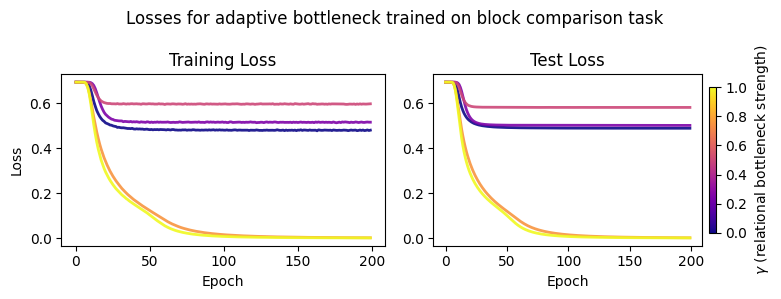

In [9]:
# Example gamma sweep
gammas = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
epochs = np.arange(len(next(iter(results.values()))["train_loss"]))

# Colormap setup
cmap = cm.plasma
norm = Normalize(vmin=gammas.min(), vmax=gammas.max())

fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharex=True)

# -------------------------
# Training loss panel
# -------------------------
for g in gammas:
    color = cmap(norm(g))
    axes[0].plot(
        epochs,
        results[g]["train_loss"],
        color=color,
        linewidth=2,
        alpha=0.9
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")

# -------------------------
# Testing loss panel
# -------------------------
for g in gammas:
    color = cmap(norm(g))
    axes[1].plot(
        epochs,
        results[g]["test_loss"],
        color=color,
        linewidth=2,
        alpha=0.9
    )

axes[1].set_title("Test Loss")
axes[1].set_xlabel("Epoch")

# -------------------------
# Colorbar (shared)
# -------------------------
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1],
    location="right",
    pad=0.02,
    shrink=0.85
)
cbar.set_label(r"$\gamma$ (relational bottleneck strength)")
plt.suptitle("Losses for adaptive bottleneck trained on block comparison task", fontsize=12)

plt.tight_layout()
plt.show()